In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

NAVY, BLUE, LIGHT, RED = "#0B1F3A", "#2E6FDB", "#9DB8E8", "#E4572E"

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": NAVY,
    "axes.titleweight": "bold",
    "axes.labelcolor": NAVY,
})

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

In [10]:
DATA_PATH = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df_raw = pd.read_csv(DATA_PATH)
print("Dataset shape:", df_raw.shape)
df_raw.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df_raw.info()
df_raw.describe(include="all").T
df_raw.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df_raw["Churn"].value_counts()
df_raw["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

the dataset is imbalanced, so accuracy alone would be misleading. A model predicting “No” for everyone gets about 73.5% accuracy and catches zero churners.

## Data dictionary

| Group | Column | Meaning | Type |
|---|---|---|---|
| ID | `customerID` | Unique identifier, no predictive value | text |
| Demographics | `gender` | Male / Female | categorical |
| | `SeniorCitizen` | 1 if aged 65+ | binary |
| | `Partner` | Has a partner | binary |
| | `Dependents` | Has dependents (children etc.) | binary |
| Account | `tenure` | Months with the company | numeric |
| | `Contract` | Month-to-month / One year / Two year | categorical |
| | `PaperlessBilling` | Receives e-bills | binary |
| | `PaymentMethod` | Electronic check, mailed check, bank transfer (auto), credit card (auto) | categorical |
| | `MonthlyCharges` | Current monthly bill | numeric |
| | `TotalCharges` | Total billed since signup (≈ tenure × monthly) | numeric |
| Services | `PhoneService` | Has phone service | binary |
| | `MultipleLines` | Several phone lines | categorical |
| | `InternetService` | DSL / Fiber optic / No | categorical |
| | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Add-on protection services | categorical |
| | `StreamingTV`, `StreamingMovies` | Streaming add-ons | categorical |
| Target | `Churn` | Left within the last month (Yes/No) | binary |

In [31]:
cat_raw = df_raw.select_dtypes(include="object").columns.drop("customerID")
for col in cat_raw:
    print(f"{col:20s} {df_raw[col].unique()}")

gender               <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner              <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents           <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService         <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines        <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService      <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity       <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup         <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection     <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport          <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV          <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies      <StringArray>
['No', 'Yes', 'No internet se

C:\Users\sonia\AppData\Local\Temp\ipykernel_22040\3742205047.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_raw = df_raw.select_dtypes(include="object").columns.drop("customerID")


Notice that the values No internet service and No phone service appear in several columns. They carry the same information as No (already encoded by InternetService / PhoneService), so we merge them in the cleaning step. Keeping them would create redundant dummy columns.

In [32]:
tc_numeric = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
print("Non-numeric TotalCharges:", tc_numeric.isna().sum())
df_raw[tc_numeric.isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Non-numeric TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [33]:
print("Duplicate customerIDs:", df_raw["customerID"].duplicated().sum())
print("Duplicate rows (without ID):", df_raw.drop(columns="customerID").duplicated().sum())
df_raw.nunique().sort_values()

Duplicate customerIDs: 0
Duplicate rows (without ID): 22


gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

In [34]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from src.preprocessing import clean_data

df = clean_data(df_raw)
print(df.shape)
df.dtypes

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(7043, 20)


gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [35]:
assert df.isna().sum().sum() == 0
df["Churn"].value_counts(normalize=True)

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

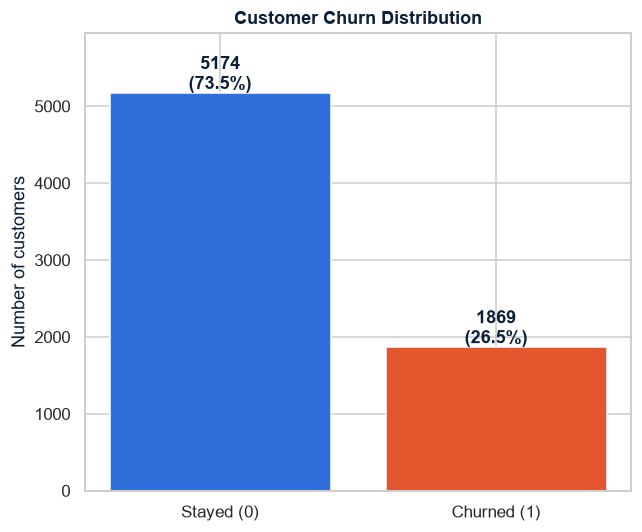

In [36]:
fig, ax = plt.subplots(figsize=(6, 5))
counts = df["Churn"].value_counts().sort_index()
bars = ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=[BLUE, RED])
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 50,
            f"{v}\n({v/len(df):.1%})", ha="center", color=NAVY, fontweight="bold")
ax.set_title("Customer Churn Distribution")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_churn_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

26.5% of customers churn. The imbalance is moderate (about 3:1), so we’ll use stratified splits, class weighting/SMOTE, and evaluate with recall, F1 and ROC-AUC rather than accuracy.

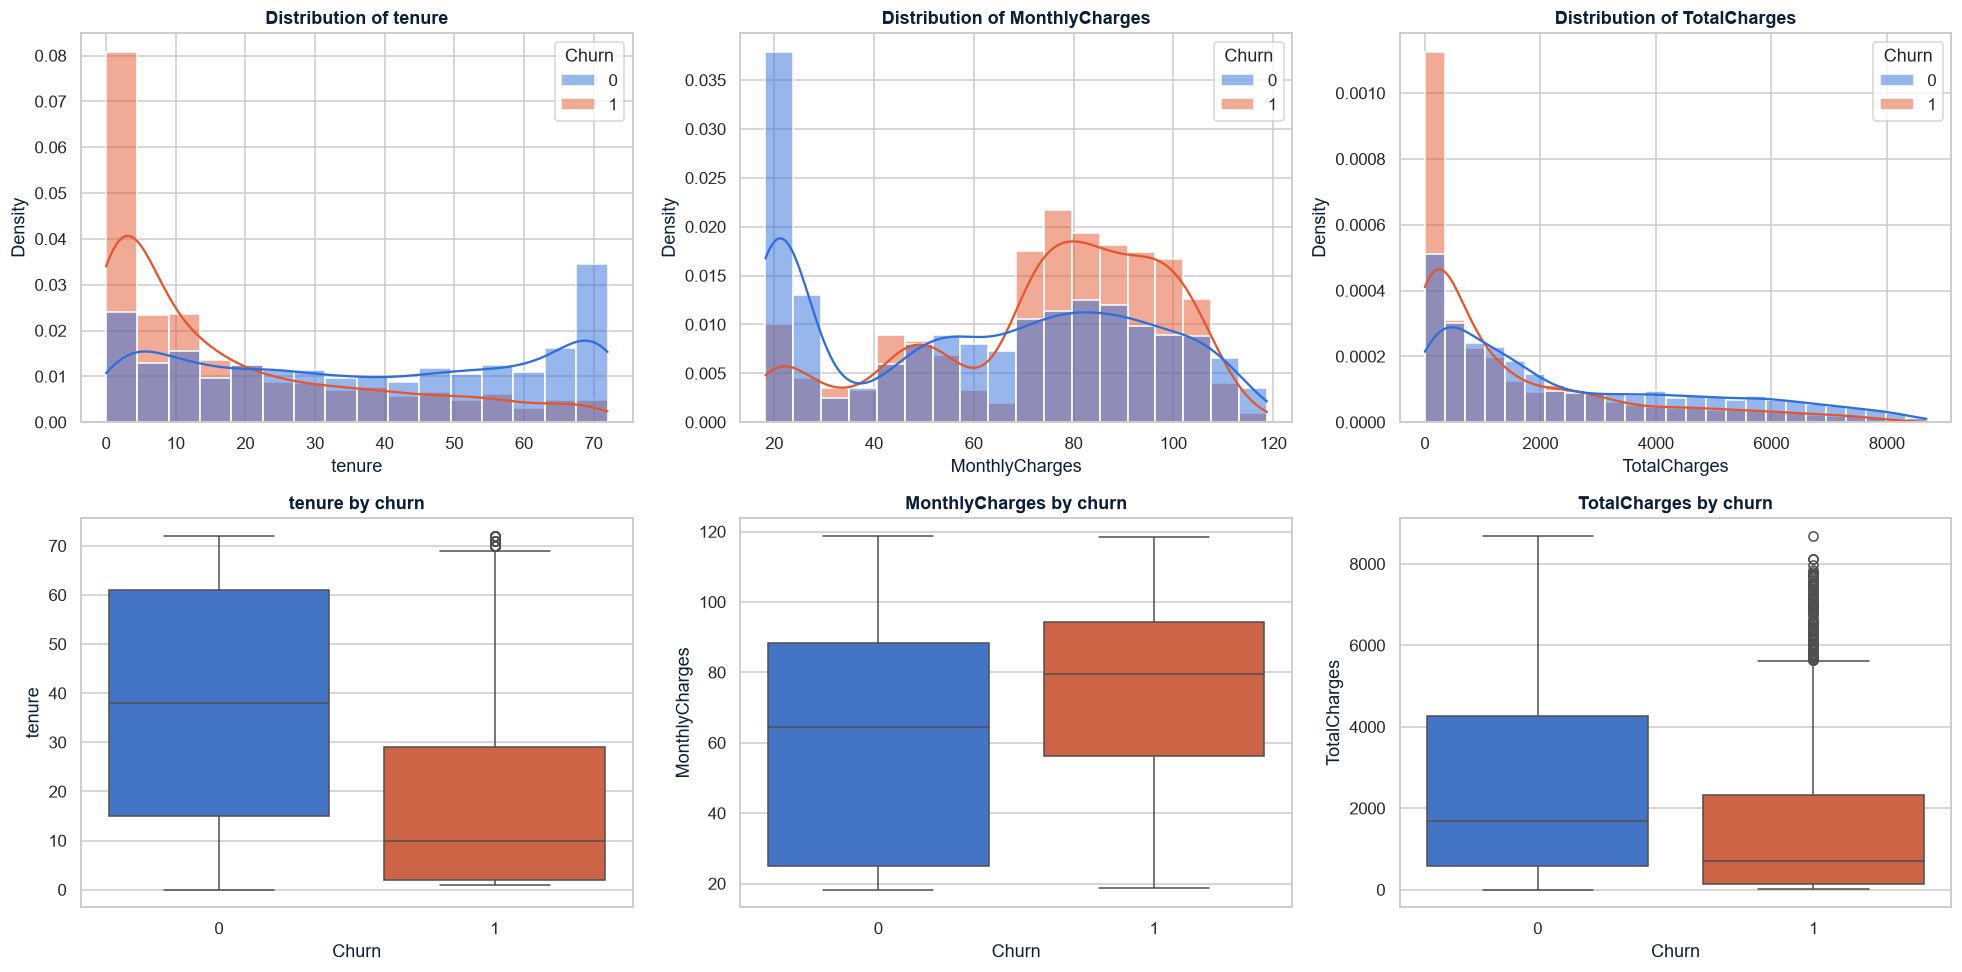

In [37]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
palette = {0: BLUE, 1: RED}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, stat="density",
                 common_norm=False, palette=palette, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", palette=palette,
                legend=False, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_numeric_vs_churn.png", dpi=200, bbox_inches="tight")
plt.show()

In [38]:
df.groupby("Churn")[num_cols].agg(["mean", "median"]).round(1)

tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
0       37.6   38.0           61.3   64.4       2549.9  1679.5
1       18.0   10.0           74.4   79.6       1531.8   703.6

### Numeric features: key observations

- **`tenure`**: churners have a much lower tenure than loyal customers (mean of about 18 vs 38 months). Most churn happens early in the customer lifecycle.
- **`MonthlyCharges`**: churners pay more on average (about 74 vs 61). Higher bills are associated with higher churn.
- **`TotalCharges`**: lower for churners, but this is mostly a side effect of low tenure, since total ≈ tenure × monthly charges. This is why we'll watch for multicollinearity later.

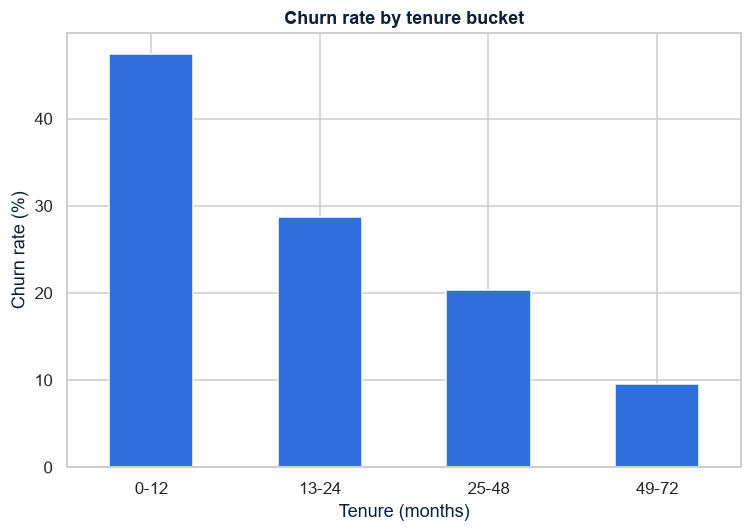

In [39]:
bins = [-1, 12, 24, 48, 72]
labels = ["0-12", "13-24", "25-48", "49-72"]
tmp = df.assign(tenure_bucket=pd.cut(df["tenure"], bins, labels=labels))
rate = tmp.groupby("tenure_bucket", observed=True)["Churn"].mean() * 100

ax = rate.plot(kind="bar", color=BLUE, figsize=(7, 5), rot=0)
ax.set_title("Churn rate by tenure bucket")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Tenure (months)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_churn_by_tenure.png", dpi=200, bbox_inches="tight")
plt.show()

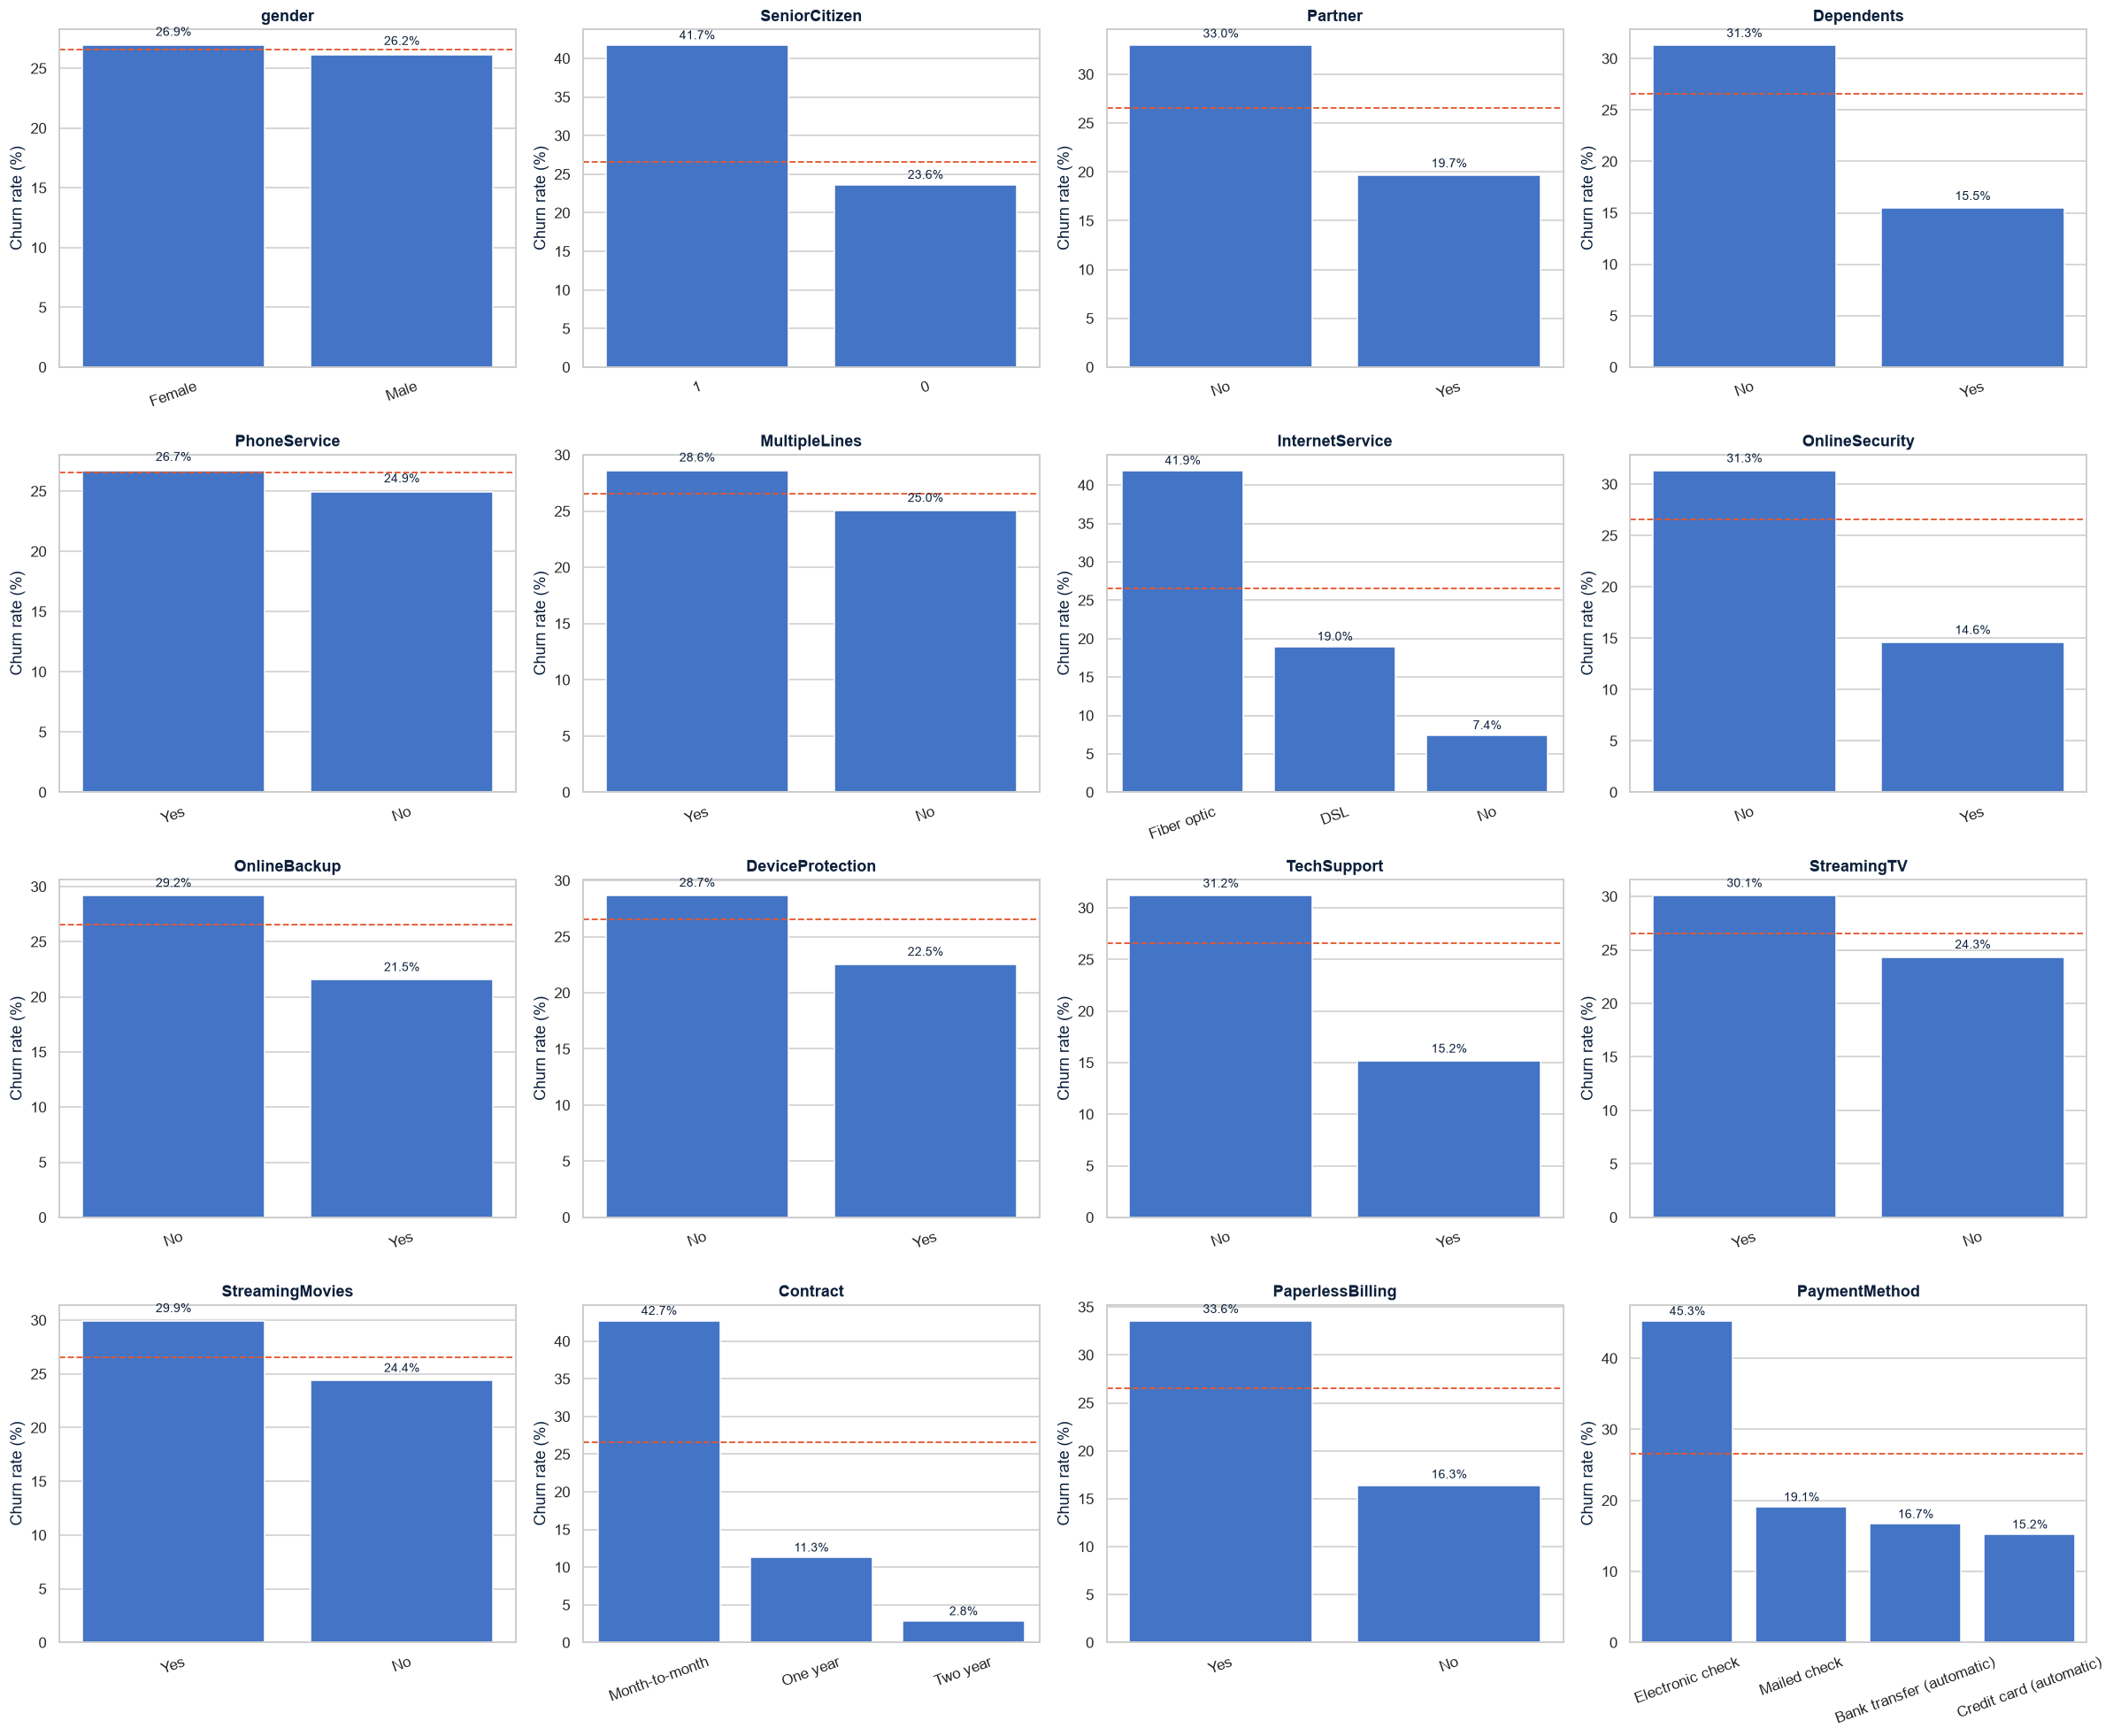

In [40]:
def plot_churn_rate(data, col, ax):
    rate = data.groupby(col)["Churn"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, color=BLUE, ax=ax)
    ax.axhline(data["Churn"].mean() * 100, color=RED, ls="--", lw=1.2,
               label="Overall churn rate")
    for p, v in zip(ax.patches, rate.values):
        ax.text(p.get_x() + p.get_width()/2, v + 0.8, f"{v:.1f}%",
                ha="center", fontsize=9, color=NAVY)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=20)

cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents",
            "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(4, 4, figsize=(22, 18))
for ax, col in zip(axes.flat, cat_cols):
    plot_churn_rate(df, col, ax)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_categorical_vs_churn.png", dpi=200, bbox_inches="tight")
plt.show()

- **`gender`**, **`PhoneService`**: almost no difference, so they’re weak predictors.
- **`Contract`**: the strongest signal. Month-to-month churns around 43%, one year about 11%, two year about 3%.
- **`InternetService`**: fiber optic is around 42% vs DSL around 19% vs no internet around 7%. Fiber is probably the more expensive plan, which fits the MonthlyCharges finding.
- **`OnlineSecurity`**, **`TechSupport`**: customers without them churn about 2-3x more.
- **`PaymentMethod`**: electronic check is around 45%, while automatic payments are around 15-17%.
- **`SeniorCitizen`**: about 42% vs 24%.
- **`PaperlessBilling`**: higher churn for paperless customers.

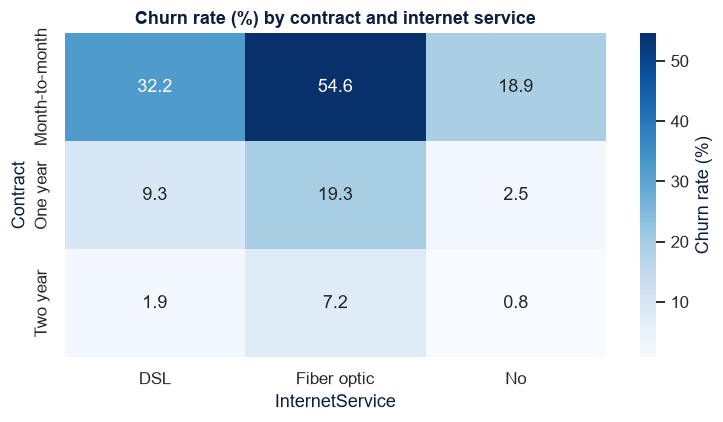

In [41]:
pivot = df.pivot_table(index="Contract", columns="InternetService",
                       values="Churn", aggfunc="mean") * 100
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate (%) by contract and internet service")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "05_contract_internet_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

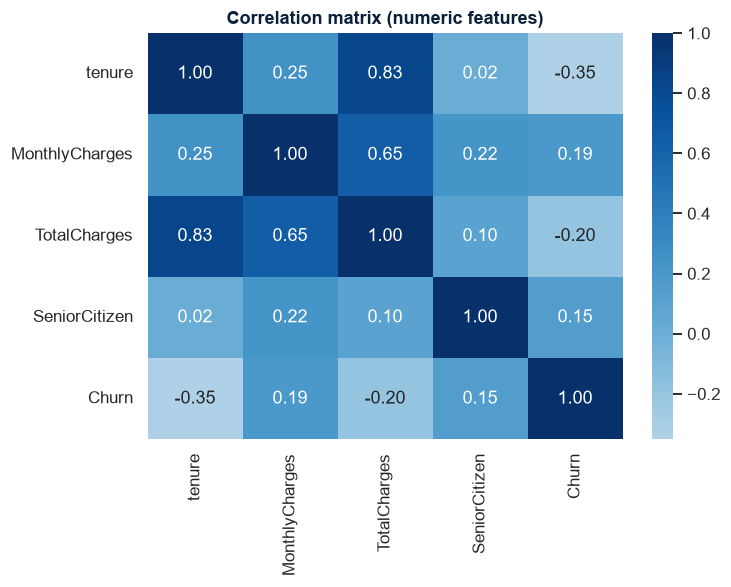

In [42]:
num_for_corr = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]]
plt.figure(figsize=(7, 5.5))
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="Blues", center=0)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "06_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [43]:
from src.preprocessing import clean_data, add_features, build_preprocessor

df = clean_data(df_raw)
df_fe = add_features(df)
print(df_fe.shape)          # (7043, 27): 26 features + Churn
df_fe[["n_addons", "avg_monthly_spend", "charge_gap", "tenure_group",
       "is_autopay", "no_protection", "monthly_fiber", "Churn"]].head()

(7043, 27)


,n_addons,avg_monthly_spend,charge_gap,tenure_group,is_autopay,no_protection,monthly_fiber,Churn
0,1,29.850000,0.000000,0-12,0,1,0,0
1,2,55.573529,1.376471,25-48,0,0,0,0
2,2,54.075000,-0.225000,0-12,0,0,0,1
3,3,40.905556,1.394444,25-48,1,0,0,0
4,0,75.825000,-5.125000,0-12,0,1,1,1


### Engineered features

| Feature | Idea | Linked EDA finding |
|---|---|---|
| `n_addons` | Customers with more services are more "attached" | Add-on services reduce churn |
| `avg_monthly_spend` | Real historical spend vs current bill | `MonthlyCharges` vs `TotalCharges` |
| `charge_gap` | Is the customer paying more than before? | Higher bills go with higher churn |
| `tenure_group` | Non-linear lifecycle effect | Churn is concentrated in the first year |
| `is_autopay` | Automatic payment lowers friction | Electronic check has the highest churn |
| `no_protection` | Internet customers with no security or support | `TechSupport` and `OnlineSecurity` |
| `monthly_fiber` | Interaction of the two strongest signals | Contract × InternetService heatmap |

**Note on `no_protection`:** it requires `InternetService != "No"`. Without that condition, customers with no internet at all would be flagged, which is wrong, since they simply can't have those services.

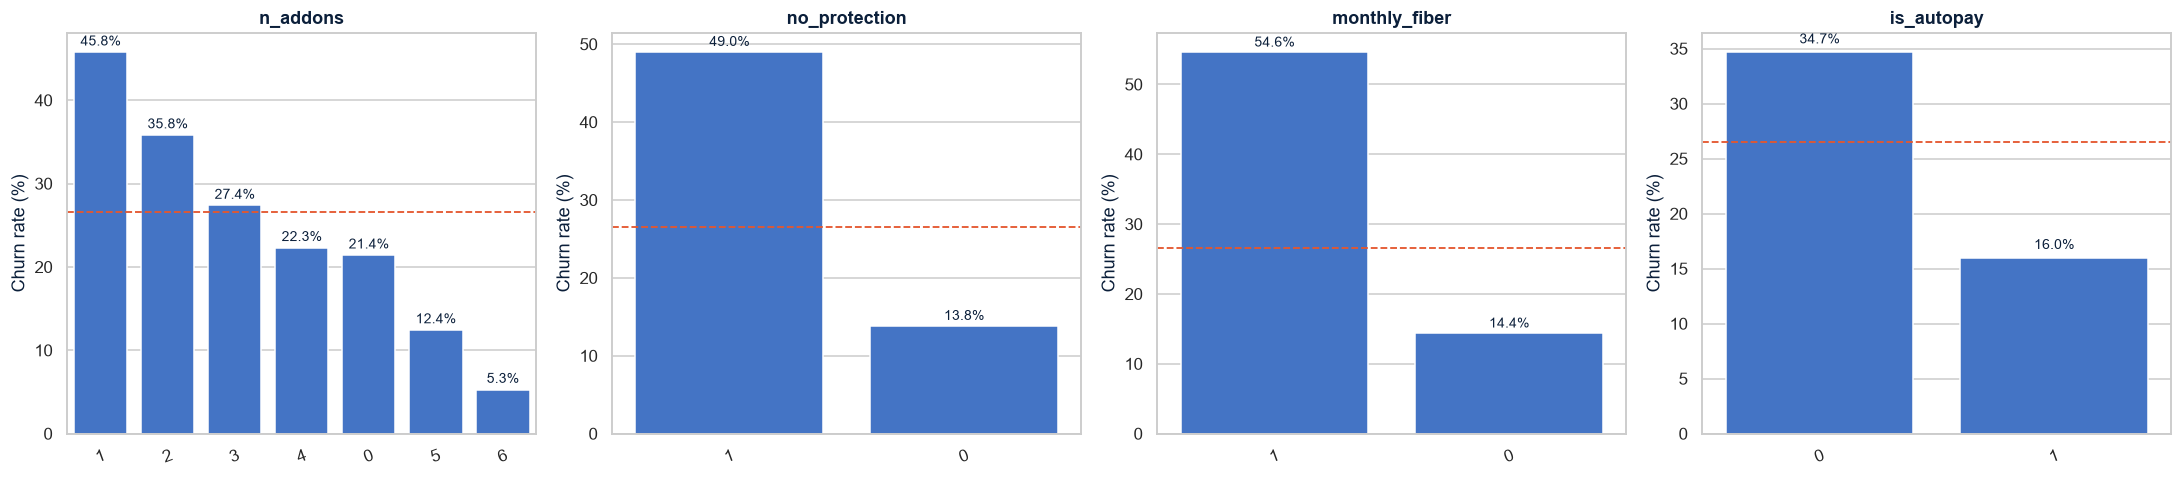

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, ["n_addons", "no_protection", "monthly_fiber", "is_autopay"]):
    plot_churn_rate(df_fe, col, ax)      # the helper from Step 9
plt.tight_layout()
plt.savefig(RESULTS_DIR / "07_engineered_features.png", dpi=200, bbox_inches="tight")
plt.show()

In [45]:
new_num = ["n_addons", "avg_monthly_spend", "charge_gap",
           "is_autopay", "no_protection", "monthly_fiber"]
(df_fe[new_num + ["Churn"]].corr()["Churn"].drop("Churn")
 .sort_values().round(3))

is_autopay          -0.210
n_addons            -0.088
charge_gap           0.002
avg_monthly_spend    0.193
no_protection        0.383
monthly_fiber        0.418
Name: Churn, dtype: float64

In [46]:
from sklearn.model_selection import train_test_split

X = df_fe.drop(columns="Churn")
y = df_fe["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Churn rate train: {y_train.mean():.3%} | test: {y_test.mean():.3%}")

Train: (5634, 26)  Test: (1409, 26)
Churn rate train: 26.535% | test: 26.544%


In [47]:
prep = build_preprocessor()
X_train_t = prep.fit_transform(X_train)     # fit ONLY on train
X_test_t = prep.transform(X_test)           # transform only

print(X_train_t.shape, X_test_t.shape)
print("NaN left:", X_train_t.isna().sum().sum())
X_train_t.head()

(5634, 36) (1409, 36)
NaN left: 0


,num__tenure,num__MonthlyCharges,num__TotalCharges,num__n_addons,num__avg_monthly_spend,num__charge_gap,bin__SeniorCitizen,bin__is_autopay,bin__no_protection,bin__monthly_fiber,...,cat__Contract_Two year,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,cat__tenure_group_0-12,cat__tenure_group_13-24,cat__tenure_group_25-48,cat__tenure_group_49-72
3738,0.102371,-0.521976,-0.262257,0.507935,-0.539986,0.226917,0,0,1,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.503635,-0.570530,0.391496,-0.639564,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4860,-0.793155,-0.809013,-0.749883,0.507935,-0.646102,-1.867855,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3867,-0.263980,0.284384,-0.172722,1.047168,0.276552,0.081601,0,1,1,0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3810,-1.281624,-0.676279,-0.989374,-1.109762,-0.674608,0.003149,0,0,1,0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [48]:
X_train_t.filter(like="num__").describe().loc[["mean", "std"]].round(2)

,num__tenure,num__MonthlyCharges,num__TotalCharges,num__n_addons,num__avg_monthly_spend,num__charge_gap
mean,-0.0,-0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [49]:
list(X_train_t.columns)

['num__tenure',
 'num__MonthlyCharges',
 'num__TotalCharges',
 'num__n_addons',
 'num__avg_monthly_spend',
 'num__charge_gap',
 'bin__SeniorCitizen',
 'bin__is_autopay',
 'bin__no_protection',
 'bin__monthly_fiber',
 'cat__gender_Male',
 'cat__Partner_Yes',
 'cat__Dependents_Yes',
 'cat__PhoneService_Yes',
 'cat__MultipleLines_Yes',
 'cat__InternetService_DSL',
 'cat__InternetService_Fiber optic',
 'cat__InternetService_No',
 'cat__OnlineSecurity_Yes',
 'cat__OnlineBackup_Yes',
 'cat__DeviceProtection_Yes',
 'cat__TechSupport_Yes',
 'cat__StreamingTV_Yes',
 'cat__StreamingMovies_Yes',
 'cat__Contract_Month-to-month',
 'cat__Contract_One year',
 'cat__Contract_Two year',
 'cat__PaperlessBilling_Yes',
 'cat__PaymentMethod_Bank transfer (automatic)',
 'cat__PaymentMethod_Credit card (automatic)',
 'cat__PaymentMethod_Electronic check',
 'cat__PaymentMethod_Mailed check',
 'cat__tenure_group_0-12',
 'cat__tenure_group_13-24',
 'cat__tenure_group_25-48',
 'cat__tenure_group_49-72']

- **`StandardScaler`** on numeric features: needed for Logistic Regression, harmless for trees.
- **`OneHotEncoder(drop="if_binary")`**: Yes/No columns become one column instead of two, and multi-class ones get one column per category.
- **`handle_unknown="ignore"`**: so an unseen category at prediction time doesn’t crash the model.
- **`Passthrough`** for the 0/1 flags: they’re already encoded.

### Class imbalance strategies

We compare three strategies on two very different models (linear and boosted trees):

| Strategy | What it does |
|---|---|
| `none` | Baseline, no correction |
| `class_weight` | Penalizes errors on the minority class more (`class_weight="balanced"`, or `scale_pos_weight` for XGBoost) |
| `smote` | Creates synthetic churners, **inside each training fold only** |

In [50]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos                    # about 2.77
print("scale_pos_weight =", round(spw, 2))

def make_model(name, class_weight=None, scale_pos_weight=1.0):
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, class_weight=class_weight)
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                         scale_pos_weight=scale_pos_weight,
                         eval_metric="logloss", random_state=42, n_jobs=-1)

strategies = {
    "none":         dict(smote=False, cw=None,       spw=1.0),
    "class_weight": dict(smote=False, cw="balanced", spw=spw),
    "smote":        dict(smote=True,  cw=None,       spw=1.0),
}

scale_pos_weight = 2.77


In [51]:
rows = []
for model_name in ["Logistic Regression", "XGBoost"]:
    for strat_name, s in strategies.items():
        steps = [("prep", build_preprocessor())]
        if s["smote"]:
            steps.append(("smote", SMOTE(random_state=42)))
        steps.append(("model", make_model(model_name, s["cw"], s["spw"])))
        pipe = ImbPipeline(steps)

        scores = cross_validate(pipe, X_train, y_train, cv=cv,
                                scoring=["precision", "recall", "f1", "roc_auc"],
                                n_jobs=-1)
        rows.append({
            "model": model_name, "strategy": strat_name,
            "precision": scores["test_precision"].mean(),
            "recall":    scores["test_recall"].mean(),
            "f1":        scores["test_f1"].mean(),
            "roc_auc":   scores["test_roc_auc"].mean(),
        })

imb_results = pd.DataFrame(rows).round(3)
imb_results.to_csv(RESULTS_DIR / "imbalance_strategies.csv", index=False)
imb_results

,model,strategy,precision,recall,f1,roc_auc
0,Logistic Regression,none,0.666,0.535,0.592,0.846
1,Logistic Regression,class_weight,0.516,0.793,0.625,0.845
2,Logistic Regression,smote,0.524,0.781,0.627,0.841
3,XGBoost,none,0.659,0.522,0.581,0.842
4,XGBoost,class_weight,0.532,0.757,0.625,0.843
5,XGBoost,smote,0.609,0.611,0.610,0.840


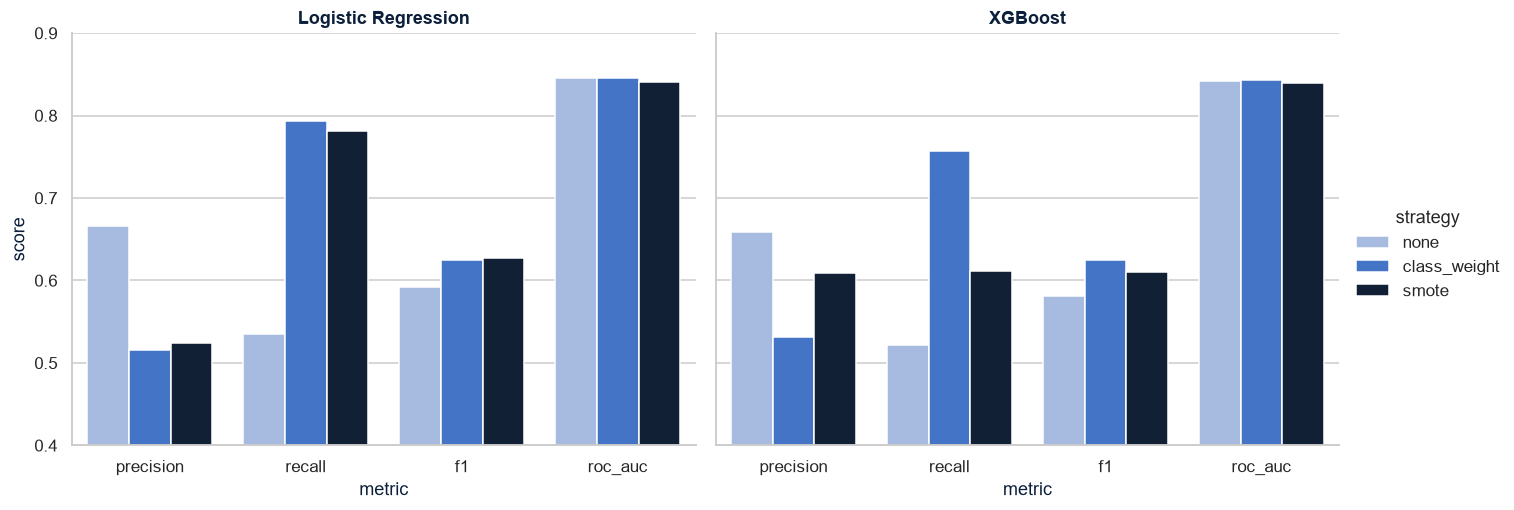

In [52]:
plot_df = imb_results.melt(id_vars=["model", "strategy"],
                           value_vars=["precision", "recall", "f1", "roc_auc"],
                           var_name="metric", value_name="score")

g = sns.catplot(data=plot_df, x="metric", y="score", hue="strategy", col="model",
                kind="bar", palette=[LIGHT, BLUE, NAVY], height=4.8, aspect=1.3)
g.set_titles("{col_name}")
g.set(ylim=(0.4, 0.9))
g.savefig(RESULTS_DIR / "08_imbalance_strategies.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretation of the imbalance experiment

**Context.** Only about 26.5% of customers churn, so a model can reach about 73% accuracy by predicting "stays" for everyone while catching zero churners. To fix this, we tested three strategies (none, `class_weight`, `smote`) on Logistic Regression and XGBoost, using 5-fold stratified cross-validation. Resampling and weighting were applied **inside each training fold only**, so the validation folds stay untouched and the scores are not inflated.

**Results (mean over 5 folds, training set only).**

| Model | Strategy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | none | 0.666 | 0.535 | 0.592 | 0.846 |
| | class_weight | 0.516 | 0.793 | 0.625 | 0.845 |
| | smote | 0.524 | 0.781 | 0.627 | 0.841 |
| XGBoost | none | 0.659 | 0.522 | 0.581 | 0.842 |
| | class_weight | 0.532 | 0.757 | 0.625 | 0.843 |
| | smote | 0.609 | 0.611 | 0.610 | 0.840 |

#### 1. ROC-AUC barely changes

ROC-AUC measures how well the model **ranks** customers: does a churner get a higher risk score than a loyal customer? It is computed across all possible thresholds. Class weighting and SMOTE mostly change **where the decision threshold ends up** (the default 0.5), not the quality of the ranking. That is why ROC-AUC stays almost identical across strategies (between 0.840 and 0.846).

#### 2. Recall increases, precision decreases

- **Recall** = among the customers who really churned, the share we caught.
- **Precision** = among the customers we flagged as churners, the share who really churned.

Without correction, the model is conservative: it flags a customer only when it is very sure. That gives high precision (about 0.66), but it **misses almost half of the churners** (recall of only 0.52-0.54). With `class_weight`, errors on churners count more, so the model flags more customers. Recall rises to 0.79 for Logistic Regression (+26 points) and 0.76 for XGBoost (+24 points), but precision falls to 0.52 and 0.53, which means more false alarms. SMOTE has the same effect on Logistic Regression (recall 0.78), but a much weaker one on XGBoost (recall 0.61, precision 0.61).

This is a trade-off, not a free improvement: we are moving along the same precision-recall curve.

#### 3. F1 improves slightly

F1 is the harmonic mean of precision and recall. Recall rises more than precision falls, so F1 goes from 0.58-0.59 to 0.625 with `class_weight`. The gain is small, so F1 alone is not enough to choose a strategy, and we also need to look at what the business cares about.

#### 4. Business reading

The two types of errors don't cost the same:

| Error | What happens | Cost |
|---|---|---|
| **False negative** (missed churner) | The customer leaves and we lose their future revenue | High |
| **False positive** (false alarm) | We send a retention offer to someone who would have stayed | Low (a discount or a call) |

Because a lost customer costs more than an unnecessary offer, **a higher recall is worth the lower precision**. This is why we do not keep the "no correction" baseline.

#### 5. Decision

| Model | class_weight (recall / F1) | smote (recall / F1) |
|---|---|---|
| Logistic Regression | 0.793 / 0.625 | 0.781 / 0.627 |
| XGBoost | 0.757 / 0.625 | 0.611 / 0.610 |

For Logistic Regression the two strategies are equivalent (the 0.002 F1 difference is negligible). For XGBoost, `class_weight` is clearly better at catching churners. We therefore choose **`class_weight`** because:
- it performs at least as well as SMOTE for both models;
- it is simpler (a single parameter, no extra step in the pipeline);
- it is faster to train;
- it does not create synthetic data, so there are no artifacts to worry about.

#### 6. Limitation of SMOTE in this project

SMOTE creates a new synthetic customer by **interpolating between a churner and its nearest neighbors**. After one-hot encoding, our categorical features are 0/1 columns, so interpolation can produce values such as 0.37 for "Contract_Two year", which doesn't correspond to any real customer. `SMOTENC` handles categorical variables properly, but it requires the indices of the categorical columns, which is more complex to set up in our pipeline (the encoding happens inside it). This may partly explain why SMOTE is less effective with XGBoost here, and it is a possible improvement for future work.